# Содержание

1. [Загрузка данных](#s1)
   - [1.1 Таблица названий параметров](#s1_1)
   - [1.2 Данные приборов учета котлоагрегата](#s1_2)


2. [Предобработка данных](#s2)
   - [2.1 Восстановление потерянных временных точек](#s2_1)
   - [2.2 Замена недостоверных данных](#s2_2)
   - [2.3 Удаление избыточных данных](#s2_3)
   - [2.4 Определение рабочих периодов](#s2_4)
   - [2.5 Тренды и сезонность](#s2_5)
   - [2.6 Проверка стационарности](#s2_6)

3. [Вывод](#s3)

<div style="border:solid purple 5px; padding: 20px"> 


<b>Цель проекта</b>

<hr>
Создать систему раннего оповещения о развитии аварийных режимов водно-химического режима котла, основанную на анализе многомерных временных рядов  с дифференциацией типов уноса для выбора корректной корректирующей стратегии.

<hr>
    
В данной тетради проводится  Data Preprocessing: <b> очистка, трансформация, обработка пропусков и выбросов, отбор признаков. </b> 

**columns.xlsx** - таблица обозначений кодов параметров 

**chemic.csv** - данные с приборов учета за 2017 года. 
       
<hr>

Для построения графиков, полученных из SCADA-системы, используется библиотека для визуализации <b> modulekrug </b>   

</div>  

### Загрузка библиотек

In [1]:
#!pip install pyod

In [2]:
#!pip install ruptures

In [3]:
%load_ext autoreload
%autoreload 2

In [4]:
import warnings
warnings.filterwarnings('ignore')

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns

In [6]:
import sys
from pathlib import Path
sys.path.append(str(Path('..').resolve()))

In [7]:
from mypackage import modulekrug

In [8]:
import re

In [9]:
import math

In [10]:
import ruptures as rpt

In [11]:
from scipy import stats

In [12]:
from datetime import datetime as dt

In [13]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [14]:
# Снимаем ограничение на количество отображаемых столбцов
pd.set_option('display.max_columns', None)

In [15]:
data_dir =  Path('../data')
note_dir = Path('../notebooks')
figures_dir = Path('../reports/figures')

### Функции

In [16]:
# Функция выводит сведение о датасете, статистику и проверяет хронологию в данных. 
def data_info(data):
    
    print()
    print('Размер таблицы:', data.shape)
    
    if data.index.is_monotonic_increasing == True:
        print(f'Данные расположены в хронологическом порядке.\n')
        print(f'Временной диапазон данных {[data.index[0]]} - {[data.index[-1]]}\n')
    else:
        print(f'Необходимо отсортировать данные в хронологическом порядке.\n')
    
    display(data.head(5))
    display(data.describe())
    display(data.info())

In [17]:
def add_savefig(list_parametrs, name):
    params_str = '_'.join(str(p) for p in list_parametrs)
    if len(params_str) > 33:
        params_str = params_str[:33] + f'_and_{len(list_parametrs)-3}more'
    filename = f'{name}_{params_str}.png'
    plt.savefig(figures_dir/filename , dpi=150, bbox_inches='tight')

In [18]:
# Функция строит гистограмму распределения данных
def histplot_trends(data, parametrs, n_sample=500):
    n = len(parametrs)
    ncols = min(3, n)
    nrows = math.ceil(n / ncols)

    data[parametrs].sample(n_sample).hist(
        figsize=(4 * ncols, 3 * nrows),
        layout=(nrows, ncols),
        bins=30,
        color='green',
        density=True
    )
    plt.suptitle(f'Распределение признаков (выборка n={n_sample})', fontsize=14, ha='left', x=0.02, y=0.995)
    plt.tight_layout()
    add_savefig(parametrs,'histplot')
    plt.show()

In [19]:
def boxplots_for_month(data, parametrs):
    """
    Строит диаграммы размаха для указанных параметров по месяцам.
    
    """
    n_params = len(parametrs)
    
    fig, axes = plt.subplots(n_params, 1, figsize=(8, 3.5 * n_params))
    
    # Если только один график, преобразуем axes в список
    if n_params == 1:
        axes = [axes]
    
    for idx, param in enumerate(parametrs):
        name = modulekrug.get_name(param)['name'].iloc[0]
        sns.boxplot(data=data, x='month', y=param, ax=axes[idx])
        axes[idx].set_title(f'{param} - {name}', fontsize=10)
        axes[idx].set_ylabel(param)
        axes[idx].set_xlabel('Месяц', fontsize=8)
        axes[idx].tick_params(axis='x', labelsize=9, colors='#008080')
        axes[idx].tick_params(axis='y', labelsize=9, colors='#008080')
    
    fig.suptitle('Диаграмма размаха по месяцам', fontsize=14, y=1.02)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    add_savefig(parametrs,'boxplot')
    plt.show() 

## <a id="s1"></a> 1. Загрузка данных

### <a id="s1_1"></a> 1.1 Таблица названий параметров

In [20]:
df_head = pd.read_excel(data_dir/'columns.xlsx')

In [21]:
df_head.head()

,had10ct101,had10ct102,had10ct103,had10ct104,had10ct105,had10ct106,hah10ct101,lba10ct003,hal40cf001,had93cp001,hah90cp001,lba10cq204,lba10cq202,lba10cq201,had10cl001,hha10cp005,hah90ct001,hha10cp001,hah90ct002,hha10cp002,lab50cf001,had10cp001,had93cf001,lba10cf001,lba08cp001,ва132,lab50cf001.1,рв348
0,Тметалла,Тметалла,Тметалла,Тметалла,Тметалла,Тметалла,Тмет.пар,Тост.пар,Fконд на,Рводы НП,Рост.пар,Na,Эл.пров.,рН пер.п,L в бар,Ртопка 3,Тост.пар,Ртопка 1,Тост.пар,Ртопка 2,Fбольшой,Р бараб.,Fводы НП,Fост.пар,Рпара в,Разреж.,Fбольшой,Абс.P
1,бар.т1,бар.т2,бар.т3,бар.т4,бар.т5,бар.т6,отв.труб,за котл.,1впр.н.А,бар.котл,в ПСК,перегр.п,перегр.п,от котла,котла т1,вверху,в ПСК т1,вверху,в ПСК т2,вверху,пит.воды,котла,бар.котл,за котл.,8сек.ГПП,вер.топ3,пит.воды,в бараб.
2,°С,°С,°С,°С,°С,°С,°С,°С,т/час,кгс/см2,кгс/см2,мкг/л,мкСм/см,рН,мм,кгс/м2,°С,кгс/м2,°С,кгс/м2,т/час,кгс/см2,т/час,т/час,кгс/см2,кгс/м2,т/час,кгс/см2
3,-50,-50,-50,-50,-50,-50,-50,-40,0,0,0,0,0,0,-315,-16,-40,-16,-40,-16,0,0,0,0,0,-16,0,0
4,900,900,900,900,900,900,900,800,25,160,160,100,5,15.3,315,16,800,16,800,16,320,160,10,304,160,16,320,0


In [22]:
df_head.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   had10ct101    5 non-null      object
 1   had10ct102    5 non-null      object
 2   had10ct103    5 non-null      object
 3   had10ct104    5 non-null      object
 4   had10ct105    5 non-null      object
 5   had10ct106    5 non-null      object
 6   hah10ct101    5 non-null      object
 7   lba10ct003    5 non-null      object
 8   hal40cf001    5 non-null      object
 9   had93cp001    5 non-null      object
 10  hah90cp001    5 non-null      object
 11  lba10cq204    5 non-null      object
 12  lba10cq202    5 non-null      object
 13  lba10cq201    5 non-null      object
 14  had10cl001    5 non-null      object
 15  hha10cp005    5 non-null      object
 16  hah90ct001    5 non-null      object
 17  hha10cp001    5 non-null      object
 18  hah90ct002    5 non-null      object
 19  hha10cp002  

In [23]:
russian_cols = [col for col in df_head.columns if re.search('[а-яА-ЯёЁ]', col)]
print("Столбцы с русскими буквами:", russian_cols)

Столбцы с русскими буквами: ['ва132', 'рв348']


In [24]:
df_head = df_head.T.reset_index()
df_head.head()

,index,0,1,2,3,4
0,had10ct101,Тметалла,бар.т1,°С,-50,900
1,had10ct102,Тметалла,бар.т2,°С,-50,900
2,had10ct103,Тметалла,бар.т3,°С,-50,900
3,had10ct104,Тметалла,бар.т4,°С,-50,900
4,had10ct105,Тметалла,бар.т5,°С,-50,900


In [25]:
df_head['name'] = df_head[0] + " " + df_head[1]
#Удалим лишние столбцы.
df_head.drop(df_head.columns[1:3], axis = 1, inplace = True)
#Новые названия столбцов
df_head = df_head.set_axis(['position', 'units', 'min', 'max', 'name'], axis = 'columns')

In [26]:
df_head['position'] = df_head['position'].str.lower()
df_head['position'] = df_head['position'].str.replace(' ', '')

In [27]:
df_head.to_csv(data_dir/'df_listparam.csv', index_label=False)

### <a id="s1_2"></a> 1.2 Данные приборов учета котлоагрегата

In [28]:
df = pd.read_csv(data_dir/'chemic.csv', index_col ='data_time', parse_dates=[0])

In [29]:
df.head()
data_info(df)


Размер таблицы: (8742, 29)
Данные расположены в хронологическом порядке.

Временной диапазон данных [Timestamp('2017-01-01 01:00:00')] - [Timestamp('2017-12-31 23:00:00')]



,HAD10CT101,HAD10CT102,HAD10CT103,HAD10CT104,HAD10CT105,HAD10CT106,HAH10CT101,LBA10CT003,HAL40CF001,HAD93CP001,HAH90CP001,LBА10CQ204,LBА10CQ202,LBA10CQ201,HAD10CL001,HHA10CP005,HAH90CT001,HHA10CP001,HAH90CT002,HHA10CP002,LAB50CF001,HAD10CP001,HAD93CF001,LBA10CF001,LBA08CP001,ва 132,LAB50CF001.1,рв348,month
data_time,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-01-01 01:00:00,-50.0,297.410034,167.492920,312.142120,310.538330,312.749237,311.082184,528.593567,0.557734,100.906013,99.694565,18.889343,1.017061,9.187409,-10.367019,-5.540329,524.024597,-4.114055,523.579895,-3.741257,180.316071,104.986763,5.776006,173.297531,97.683365,-4.478760,180.316086,105.975243,1
2017-01-01 02:00:00,-50.0,297.361725,167.398590,312.149078,310.518341,312.739227,311.016022,527.848145,0.588433,100.780128,99.556656,17.704405,1.030290,9.174880,-8.797795,-5.477137,522.886475,-4.023304,522.324585,-3.608143,180.536530,104.860405,5.770885,173.493317,97.542007,-4.356194,180.536530,105.851761,1
2017-01-01 03:00:00,-50.0,297.143860,166.955658,311.855804,310.273865,312.499512,310.895935,528.232788,0.624670,100.627426,99.401184,17.130402,0.964971,9.217010,-10.776489,-5.716572,517.675110,-4.313242,518.524963,-3.909814,180.483902,104.710243,5.767532,173.216736,97.399071,-4.654567,180.483917,105.700386,1
2017-01-01 04:00:00,-50.0,297.313721,167.103012,311.984680,310.366791,312.597015,310.879425,528.399780,0.558772,100.606224,99.368042,18.007931,1.044697,9.179220,-9.367927,-5.745860,523.403137,-4.315660,522.590271,-3.929968,180.253036,104.688377,5.767073,173.602402,97.359032,-4.649873,180.253021,105.678703,1
2017-01-01 05:00:00,-50.0,297.177551,167.056046,311.776245,310.157227,312.385010,310.713745,528.520081,0.574724,100.386505,99.141762,19.552386,1.015224,9.242821,-9.449389,-5.768147,523.734619,-4.371890,523.257324,-3.986693,180.422180,104.454094,5.759306,174.052734,97.112206,-4.698212,180.422211,105.444206,1


,HAD10CT101,HAD10CT102,HAD10CT103,HAD10CT104,HAD10CT105,HAD10CT106,HAH10CT101,LBA10CT003,HAL40CF001,HAD93CP001,HAH90CP001,LBА10CQ204,LBА10CQ202,LBA10CQ201,HAD10CL001,HHA10CP005,HAH90CT001,HHA10CP001,HAH90CT002,HHA10CP002,LAB50CF001,HAD10CP001,HAD93CF001,LBA10CF001,LBA08CP001,ва 132,LAB50CF001.1,рв348,month
count,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000,8742.000000
mean,-26.831861,234.870249,136.865162,246.954823,248.322660,247.370300,243.034229,431.984228,3.830994,76.052221,73.359109,19.784402,1.786071,8.042964,39.570476,-4.380023,404.758659,-3.579163,404.441445,-3.293508,120.180512,76.812636,2.347392,124.745585,94.982761,-3.749986,120.182433,77.802491,6.516472
std,69.686292,101.986503,56.778415,107.723225,104.098889,108.075898,112.991660,155.899257,1.918254,44.800499,43.027449,12.093463,1.150725,1.304592,145.846058,2.276165,187.292761,2.109189,187.090965,1.939883,76.427989,45.171567,1.876426,68.255330,14.648121,2.091831,76.594190,45.171808,3.443285
min,-50.000000,-50.000000,-50.000000,-50.000000,-50.000000,-50.000000,-50.000000,-40.000000,0.000000,0.000000,0.000000,1.000000,0.050192,5.500000,-333.443604,-16.471561,0.000000,-16.469370,0.000000,-16.477106,0.000000,0.000000,0.000000,0.000000,0.000000,-16.000000,0.000000,0.000000,1.000000
25%,-50.000000,116.421671,101.393258,121.251974,145.159382,122.159464,128.025711,308.311547,1.810192,4.649912,4.722269,10.946728,0.730964,6.972939,-8.134449,-5.717734,144.228070,-4.699486,144.179512,-4.270081,0.000000,4.683013,0.265596,81.285204,96.015599,-4.893668,0.000000,5.673274,4.000000
50%,-50.000000,295.928436,157.927917,311.360900,309.816300,311.984818,310.324692,518.662201,3.947016,102.750644,99.122592,16.844471,1.636763,8.676330,-2.972336,-4.965894,515.670959,-4.071606,515.259430,-3.711049,153.837066,103.806290,2.355325,151.357551,97.603252,-4.239359,153.848725,104.796825,7.000000
75%,-50.000000,297.303375,163.184772,312.477204,310.919334,313.129776,311.435684,523.283737,5.270060,104.432295,100.606865,22.548621,2.708884,9.154792,5.494697,-3.918571,520.645172,-3.178135,520.166763,-2.757542,170.059937,105.362978,3.485348,167.503013,98.815998,-3.337493,170.127152,106.353419,10.000000
max,312.626007,301.061859,317.799591,316.688629,315.032379,317.323730,325.873993,542.854919,11.153733,111.487267,104.962280,65.000000,4.000000,10.000000,324.396149,6.390378,543.104858,6.904062,542.650024,5.578177,230.745209,111.589958,9.058212,277.480713,103.101784,6.138657,324.473389,112.580284,12.000000


<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8742 entries, 2017-01-01 01:00:00 to 2017-12-31 23:00:00
Data columns (total 29 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   HAD10CT101    8742 non-null   float64
 1   HAD10CT102    8742 non-null   float64
 2   HAD10CT103    8742 non-null   float64
 3   HAD10CT104    8742 non-null   float64
 4   HAD10CT105    8742 non-null   float64
 5   HAD10CT106    8742 non-null   float64
 6   HAH10CT101    8742 non-null   float64
 7   LBA10CT003    8742 non-null   float64
 8   HAL40CF001    8742 non-null   float64
 9   HAD93CP001    8742 non-null   float64
 10  HAH90CP001    8742 non-null   float64
 11  LBА10CQ204    8742 non-null   float64
 12  LBА10CQ202    8742 non-null   float64
 13  LBA10CQ201    8742 non-null   float64
 14  HAD10CL001    8742 non-null   float64
 15  HHA10CP005    8742 non-null   float64
 16  HAH90CT001    8742 non-null   float64
 17  HHA10CP001    8742 non-null   float

None

In [30]:
print ('Дубликатов в таблице:', df.duplicated().sum())

Дубликатов в таблице: 0


In [31]:
df = df.drop_duplicates()

In [32]:
df.columns = df.columns.str.lower()
df.columns = df.columns.str.replace(' ', '')

In [33]:
russian_cols = [col for col in df.columns if re.search('[а-яА-ЯёЁ]', col)]
print("Столбцы с русскими буквами:", russian_cols)

Столбцы с русскими буквами: ['lbа10cq204', 'lbа10cq202', 'ва132', 'рв348']


In [34]:
cyrillic_to_latin = {
    'а': 'a', 'в': 'b', 'с': 'c', 'е': 'e', 'у': 'y', 'к': 'k', 
     'м': 'm', 'н': 'h', 'о': 'o', 'р': 'p', 'х': 'x'
}

def replace_cyrillic(col_name):
    for cyr, lat in cyrillic_to_latin.items():
        col_name = col_name.replace(cyr, lat)
    return col_name

rename_dict = {col: replace_cyrillic(col) for col in ['lbа10cq204', 'lbа10cq202']}

df_head = df_head.rename(columns=rename_dict)

In [35]:
#замена названия столбцов в которых смешенные алфавиты
df = df.rename(columns=rename_dict)

## <a id="s2"></a> 2. Предобработка данных

### <a id="s2_1"></a> 2.1 Восстановление потерянных временных точек

Посмотрим есть ли потери данных. Для этого добавим новое поле 'time_diff', куда запишем значения временного разрыва.

In [36]:
time_diff_values = df.index.to_series().diff().dt.total_seconds()/3600
df.insert(0, 'time_diff', time_diff_values)

In [37]:
df.groupby('time_diff')['time_diff'].count()

time_diff
1.0     8739
5.0        1
14.0       1
Name: time_diff, dtype: int64

In [38]:
start = df.index[0]
stop = df.index[-1]
print(f'Временной диапазон {start} - {stop}')

Временной диапазон 2017-01-01 01:00:00 - 2017-12-31 23:00:00


In [39]:
# Создаем временной ряд диапазона 2017-01-01 00:00:00 - 2017-12-31 23:00:00
date_rng = pd.date_range(start=start, end=stop, freq='H')

In [40]:
df_mark = pd.DataFrame(date_rng, columns=['data_time'])

In [41]:
df_mark.set_index('data_time', inplace=True)

In [42]:
df_restor = df.join(df_mark, how='right')
print(f'Количество записей до изменения: {df.shape[0]}.\n')
print(f'Количество записей после изменения: {df_restor.shape[0]}.\n')

Количество записей до изменения: 8742.

Количество записей после изменения: 8759.



In [43]:
df_restor['time_diff'] = df_restor['time_diff'].fillna(0)

Text(0.5, 1.0, 'График временных разрывов')

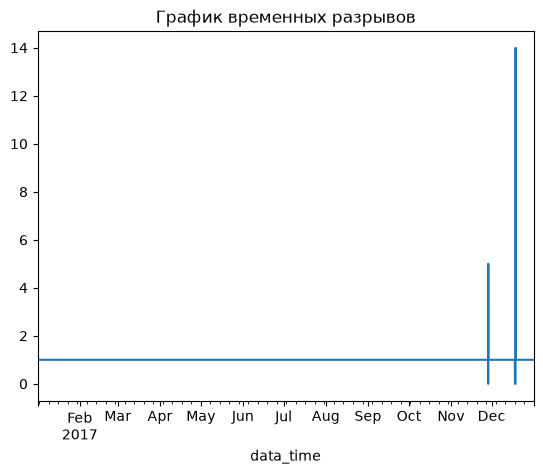

In [44]:
df_restor['time_diff'].plot()
plt.title('График временных разрывов')

In [45]:
df_restor[df_restor['time_diff']==0].head(3)

,time_diff,had10ct101,had10ct102,had10ct103,had10ct104,had10ct105,had10ct106,hah10ct101,lba10ct003,hal40cf001,had93cp001,hah90cp001,lba10cq204,lba10cq202,lba10cq201,had10cl001,hha10cp005,hah90ct001,hha10cp001,hah90ct002,hha10cp002,lab50cf001,had10cp001,had93cf001,lba10cf001,lba08cp001,ва132,lab50cf001.1,рв348,month
data_time,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2017-01-01 01:00:00,0.0,-50.0,297.410034,167.49292,312.14212,310.53833,312.749237,311.082184,528.593567,0.557734,100.906013,99.694565,18.889343,1.017061,9.187409,-10.367019,-5.540329,524.024597,-4.114055,523.579895,-3.741257,180.316071,104.986763,5.776006,173.297531,97.683365,-4.47876,180.316086,105.975243,1.0
2017-11-28 09:00:00,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-11-28 10:00:00,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Посмотрим на пропуски в данных на участке.

In [46]:
parametrs = ['had10ct101', 'рв348', 'lba10cf001']
df_view = df_restor[(df_restor.index > '2017-11-26') & (df_restor.index < '2017-11-30')][parametrs]


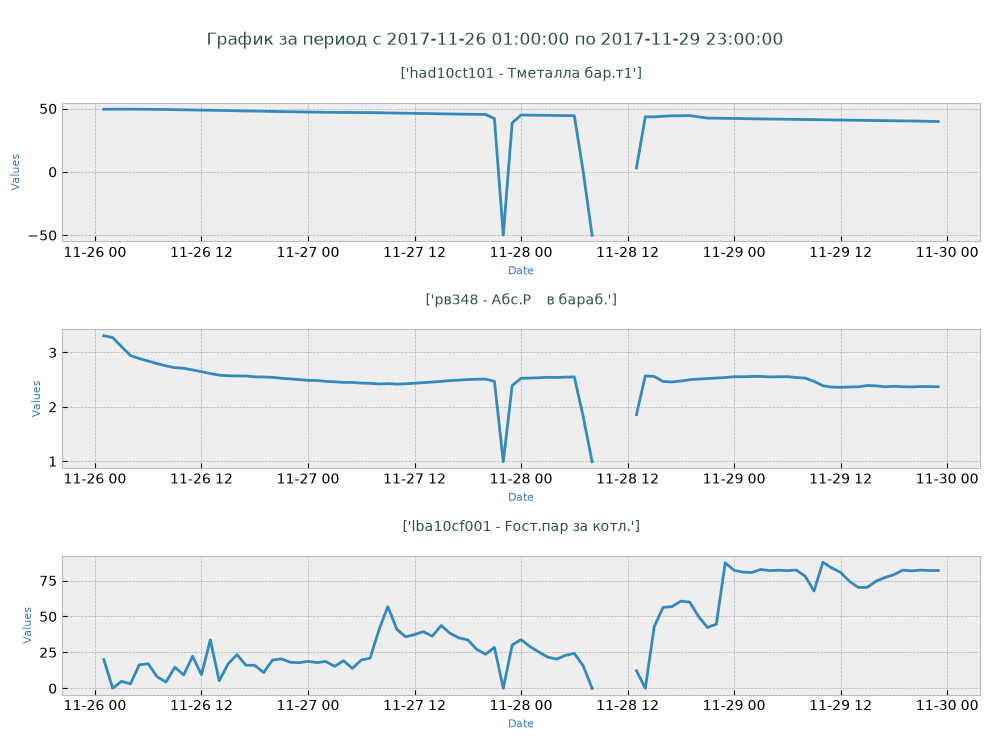

In [47]:
parametrs = ['had10ct101', 'рв348',  'lba10cf001']
modulekrug.plot_group(df_view, parametrs, value_resample = '1h', savefig=False)

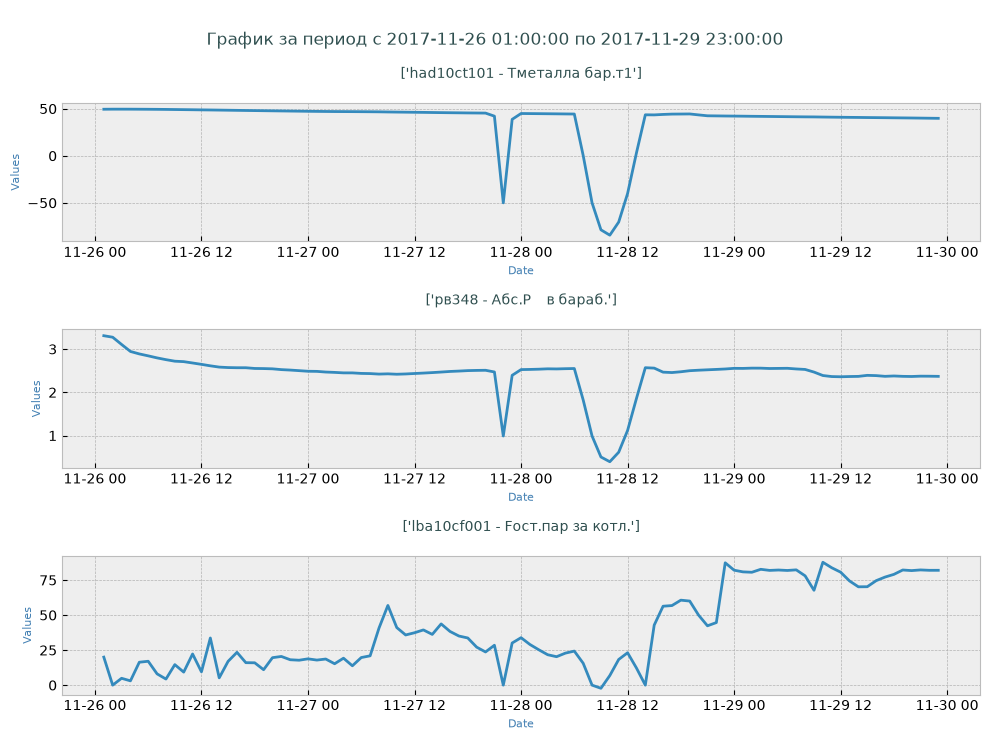

In [48]:
# Данные заполнены с помощью кубической сплайн-интерполяцией
modulekrug.plot_group(df_view.interpolate(method='cubicspline'), parametrs, value_resample = '1h', savefig=False)

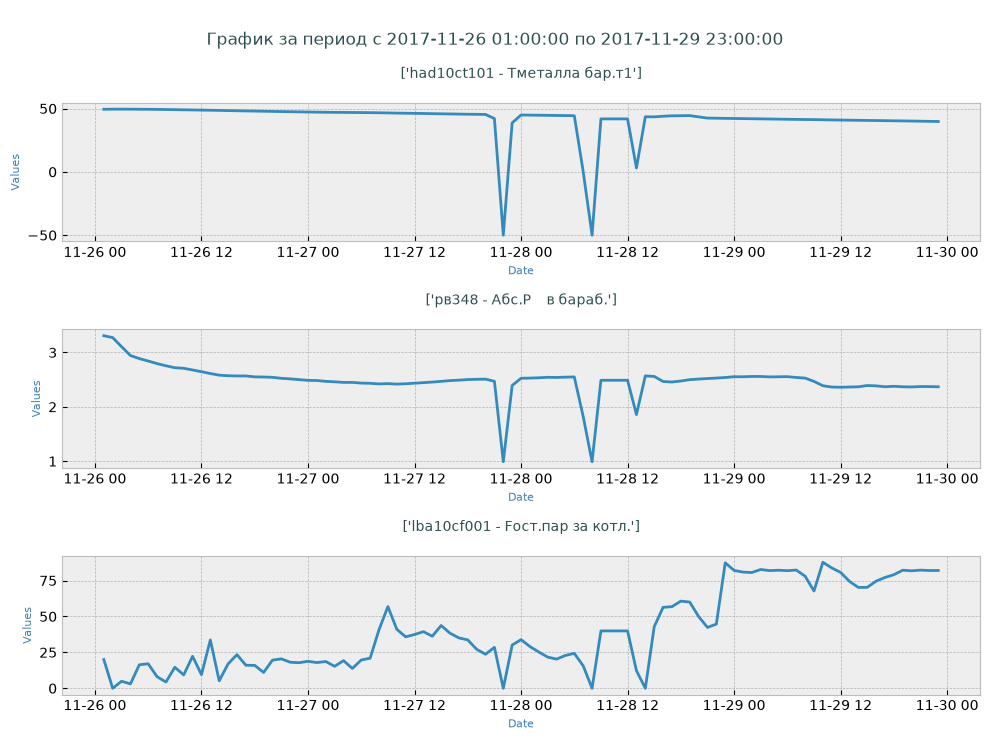

In [49]:
# Данные заполнены медианным значением
modulekrug.plot_group(df_view.fillna(df_view.mean()), parametrs, value_resample = '1h', savefig=False)

Для заполнения пропущенных данных (NaN) будем использовать линейную полиномиальную интерполяцию P(x)=a⋅x+b. Использование простейшей модели является наиболее предпочтительной, т.к. минимизирует риск внесения ложных паттернов, что мы видели на тестовом участке на примере параметра "Fост.пара за котл." при использовании кубической сплайн-интерполяции.

In [50]:
df_restor = df_restor.interpolate(method = 'polynomial', order= 1)

In [51]:
df_restor.drop('time_diff', axis = 1, inplace=True)

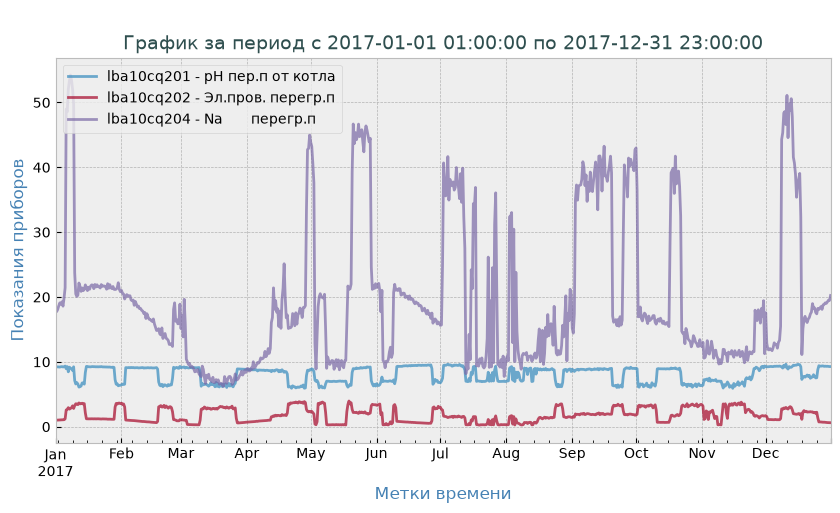

In [52]:
parametrs = ['lba10cq201', 'lba10cq202', 'lba10cq204']
modulekrug.plot_trends(df_restor, parametrs , value_resample = '12h', savefig=True)

### <a id="s2_2"></a> 2.2 Замена недостоверных данных

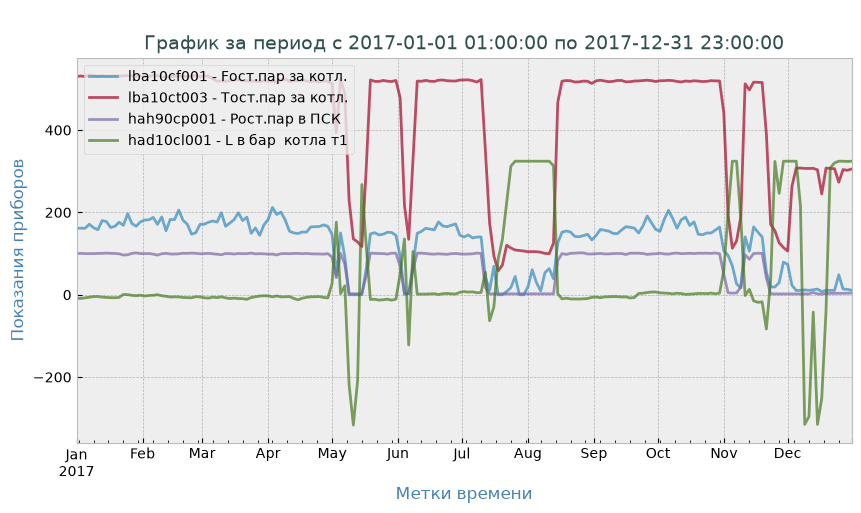

In [53]:
parametrs = ['lba10cf001', 'lba10ct003', 'hah90cp001', 'had10cl001']
modulekrug.plot_trends(df_restor, parametrs , value_resample = '48h', savefig=True)

На графике представлены одни из основных параметров работы котла: расход, температура, давление пара и уровень в барабане. На тренде отчетливо видны периоды, когда котел работал, а когда нет. Уровень в барабане при нормальных рабочих условиях должен находиться в районе нуля. Сильно высокие или низкие значения указывают на неработающий объект.

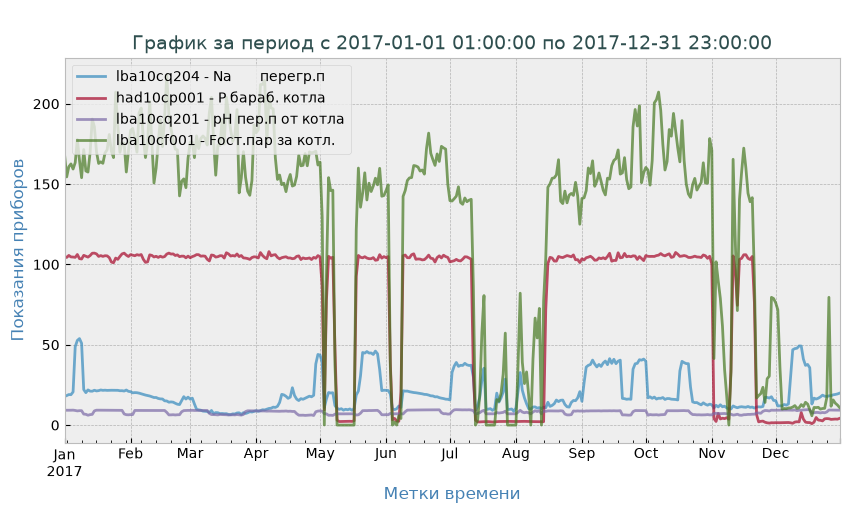

In [54]:
parametrs = ['lba10cq204', 'had10cp001', 'lba10cq201', 'lba10cf001' ]
modulekrug.plot_trends(df_restor, parametrs, value_resample = '24h', savefig=True)

In [55]:
# Список приборов учета химконтроля в барабане котла
list_cq = df_head[df_head['position'].str.contains("cq", case=False)].set_index('position')
print(f'\nТаблица параметров\n')
display(list_cq)


Таблица параметров



,units,min,max,name
position,,,,
lba10cq204,мкг/л,0,100,Na перегр.п
lba10cq202,мкСм/см,0,5,Эл.пров. перегр.п
lba10cq201,рН,0,15.3,рН пер.п от котла


In [56]:
df_restor[list_cq.index.to_list()].describe()

,lba10cq204,lba10cq202,lba10cq201
count,8759.000000,8759.000000,8759.000000
mean,19.773283,1.784869,8.041979
std,12.086086,1.150141,1.303648
min,1.000000,0.050192,5.500000
25%,10.946844,0.730970,6.974288
50%,16.829672,1.635353,8.674227
75%,22.535926,2.706353,9.153696
max,65.000000,4.000000,10.000000


In [57]:
#Приборы химконтроля должны показывать положительные значения. 
lower_bounds = list_cq['min'].to_dict()

In [58]:
df_restor[list_cq.index.to_list()] = df_restor[list_cq.index.to_list()].clip(
    lower=lower_bounds
)

### <a id="s2_3"></a> 2.3 Удаление избыточных данных

Некоторые из параметров скорее всего дублируются, например Температура металла барабана. 

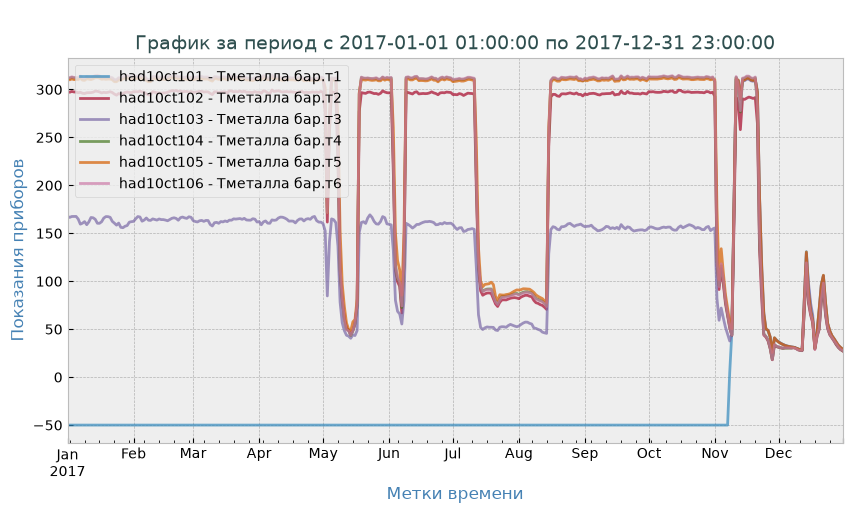

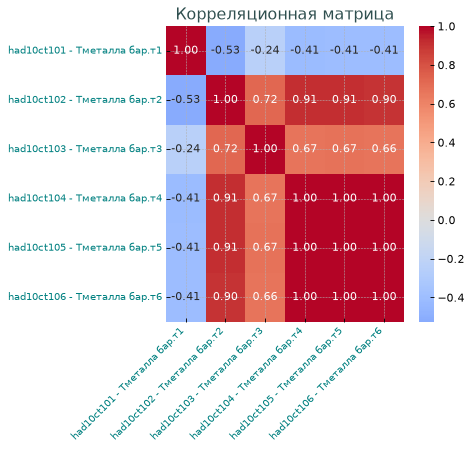

In [59]:
# Температура металла барабана в разных точках
parametrs = ['had10ct101', 'had10ct102', 'had10ct103', 'had10ct104', 
             'had10ct105', 'had10ct106']
modulekrug.plot_trends(df_restor, parametrs, value_resample = '24h', savefig=True)
modulekrug.plot_corr(df_restor, parametrs, 'spearman', print_table=False, savefig=True)

Пять параметров имеют 100% автокорреляцию. Оставим точку ('had10ct104'), остальные удалим. Первый является аномалией, т.к. большую часть времени находился в нерабочем состоянии (-50).

In [60]:
del_parametrs = ['had10ct101', 'had10ct102', 'had10ct103', 'had10ct105', 'had10ct106']
df_restor.drop(del_parametrs, axis=1, inplace=True)

Посмотрим на корреляцию остальных параметров.

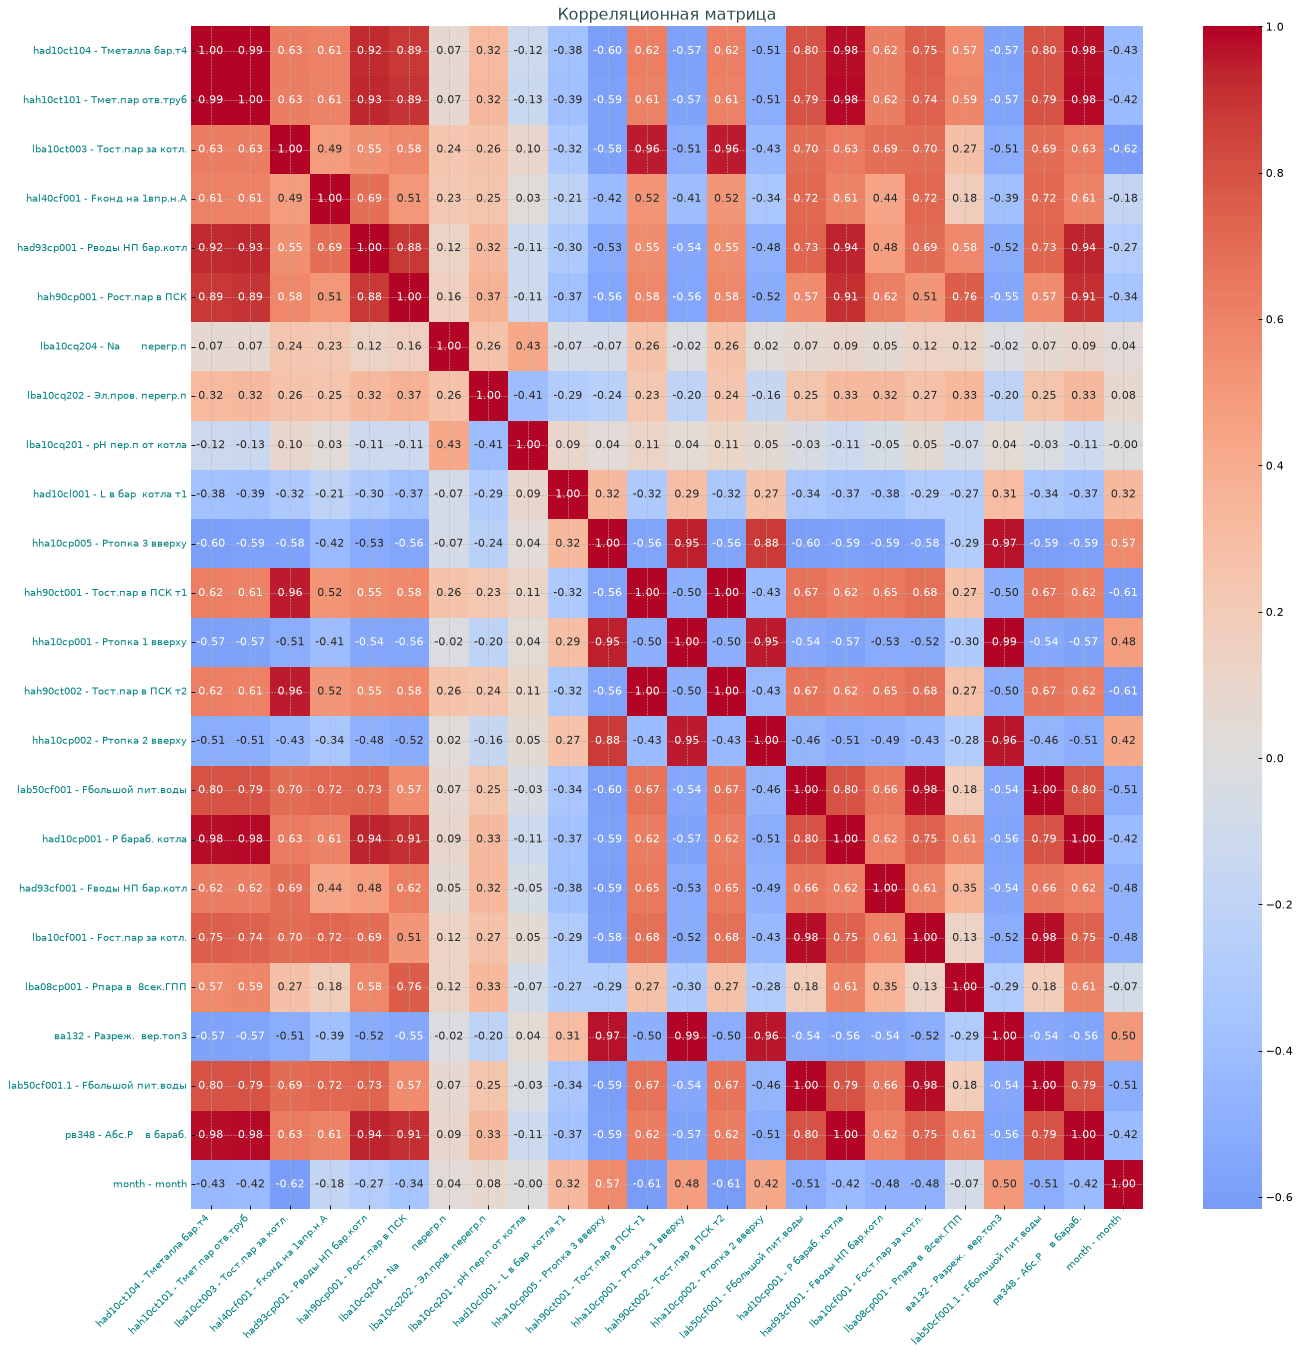

In [61]:
modulekrug.plot_corr(df_restor, df_restor.columns, 'spearman')

Температурные параметры, расходы и давления сильно коррелируют между собой, что логично. Такие параметры лишь ухудшат модель, поэтому оставим L в бар , Fост.пар, Рпара в 8сек.ГПП, Р бараб, Тост.пар и Ртопка1, т.к. они необходимы в том числе для разметки состояния котла. Так же необходимо оставить параметры химконтроля, они ключевые для нашей модели.

In [62]:
del_parametrs = ['had10ct104', 'hah10ct101', 'lba10ct003', 'had93cp001', 
'hah90cp001', 'hha10cp005', 'hah90ct002', 'hha10cp002',
'lab50cf001', 'had93cf001', 'ва132', 'lab50cf001.1', 'рв348' ]
print('Список параметров на удаление')
modulekrug.find_values_by_index(del_parametrs)

Список параметров на удаление


['had10ct104 - Тметалла бар.т4',
 'hah10ct101 - Тмет.пар отв.труб',
 'lba10ct003 - Тост.пар за котл.',
 'had93cp001 - Рводы НП бар.котл',
 'hah90cp001 - Рост.пар в ПСК',
 'hha10cp005 - Ртопка 3 вверху',
 'hah90ct002 - Тост.пар в ПСК т2',
 'hha10cp002 - Ртопка 2 вверху',
 'lab50cf001 - Fбольшой пит.воды',
 'had93cf001 - Fводы НП бар.котл',
 'ва132 - Разреж.  вер.топ3',
 'lab50cf001.1 - Fбольшой пит.воды',
 'рв348 - Абс.P    в бараб.']

In [63]:
df_restor.drop(del_parametrs, axis=1, inplace=True)

### <a id="s2_4"></a> 2.4. Определение рабочих периодов

Для корректной оценки уноса солей анализ проведем на периодах, когда котел был в работе по причине, что унос солей происходит только при наличии парообразования и отвода пара. В режиме простоя процессы переноса примесей в паровую фазу отсутствуют. Анализ только рабочих периодов позволяет связать изменения параметров пара с конкретными режимами работы котла (нагрузка, уровень в барабане, качество котловой воды). Исключение нерабочих периодов устраняет артефактные корреляции, возникающие на границах режимов, и снижает долю «шумовых» выбросов, не связанных с механизмами уноса.

Готовность котла высокого давления к подключению к паропроводу определяется выполнением строгих критериев по давлению, температуре и другим параметрам. Эти требования прописаны в нормативных документах (ПТЭ) и заводских инструкциях, чтобы исключить гидроудары и термические напряжения в металл:

- Давление на котле равно давлению в паропроводе или на 0,5–1,0 кгс/см² выше
- Температура перегретого пара отклоняется от температуры пара в магистрали не более чем на 5°С. Т.к. нет сведений о температуре пара в магистрали, примем за норму > 480°С.
- Качество пара соответствует нормам, чтобы не ухудшить качество в общем коллекторе (данные химконтроля).
- Минимальную нагрузку примем за 80 т/ч. 
Так же будем отслеживать уровень в барабане. Т.к. мы пытаемся выявить аварийные остановы котла, то примем уровень в пределах ±110мм (первый предел защит - 100мм).

Сделаем разметку данных, запишем в параметр 'work' признак нормальной работы котла.

In [64]:
df_restor['work'] = np.where(((df_restor['lba10cf001']>=80))&
                            (abs(df_restor['had10cp001'] - df_restor['lba08cp001'])<15)&
                             (df_restor['hah90ct001']>480)&
                             (abs(df_restor['had10cl001'])<110), 1, 0)

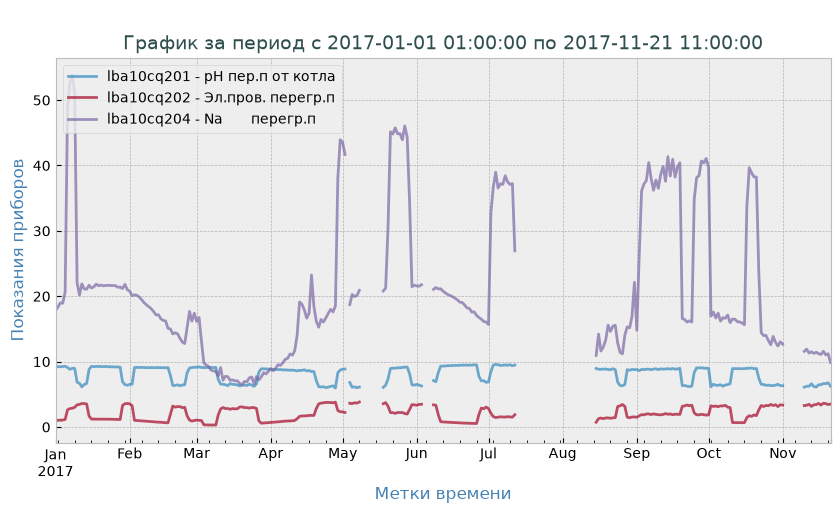

In [65]:
data_work = df_restor[df_restor['work']==1].copy()
parametrs = ['lba10cq201', 'lba10cq202', 'lba10cq204']
modulekrug.plot_trends(data_work, parametrs, '24H')

### <a id="s2_5"></a> 2.5. Тренды и сезонность

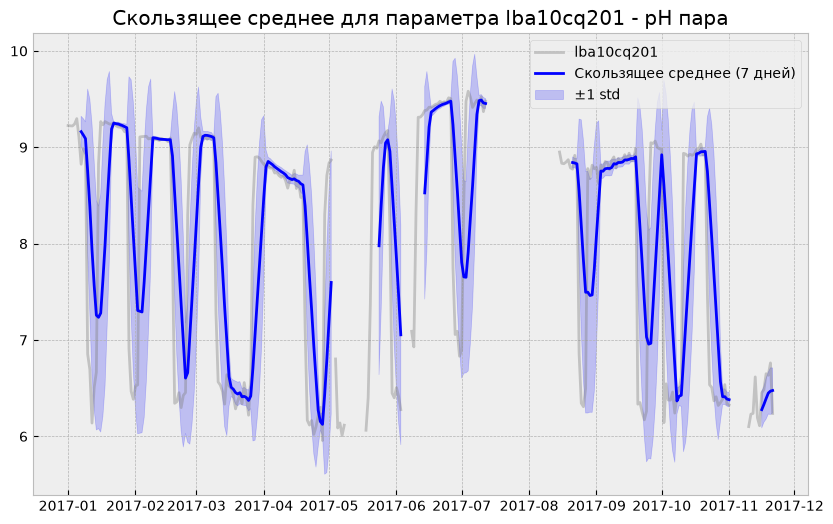

In [66]:
data = data_work[['lba10cq201']].resample('1D').mean()
data['rolling_mean'] = data['lba10cq201'].rolling(7).mean()
data['rolling_std']  = data['lba10cq201'].rolling(7).std()

plt.figure(figsize=(10, 6))
plt.plot(data.index, data['lba10cq201'], label='lba10cq201', alpha=0.4, color='gray')
plt.plot(data.index, data['rolling_mean'], label='Скользящее среднее (7 дней)', color='blue')
plt.fill_between(
    data.index,
    data['rolling_mean'] - data['rolling_std'],
    data['rolling_mean'] + data['rolling_std'],
    color='blue', alpha=0.2, label='±1 std'
)
plt.legend()
plt.title('Скользящее среднее для параметра lba10cq201 - pH пара')
plt.grid(True)
plt.show()

Анализ стационарности и поиск трендов осложнены прерывистым характером работы оборудования: данные представляют собой набор коротких рабочих циклов, разделённых длительными простоями. Суточная сезонность оценим на одном длительном непрерывном участке работы методом аддитивной декомпозиции с периодом 24 ч

Длина ряда: 2879 точек (~120.0 суток)
Пропусков: 5


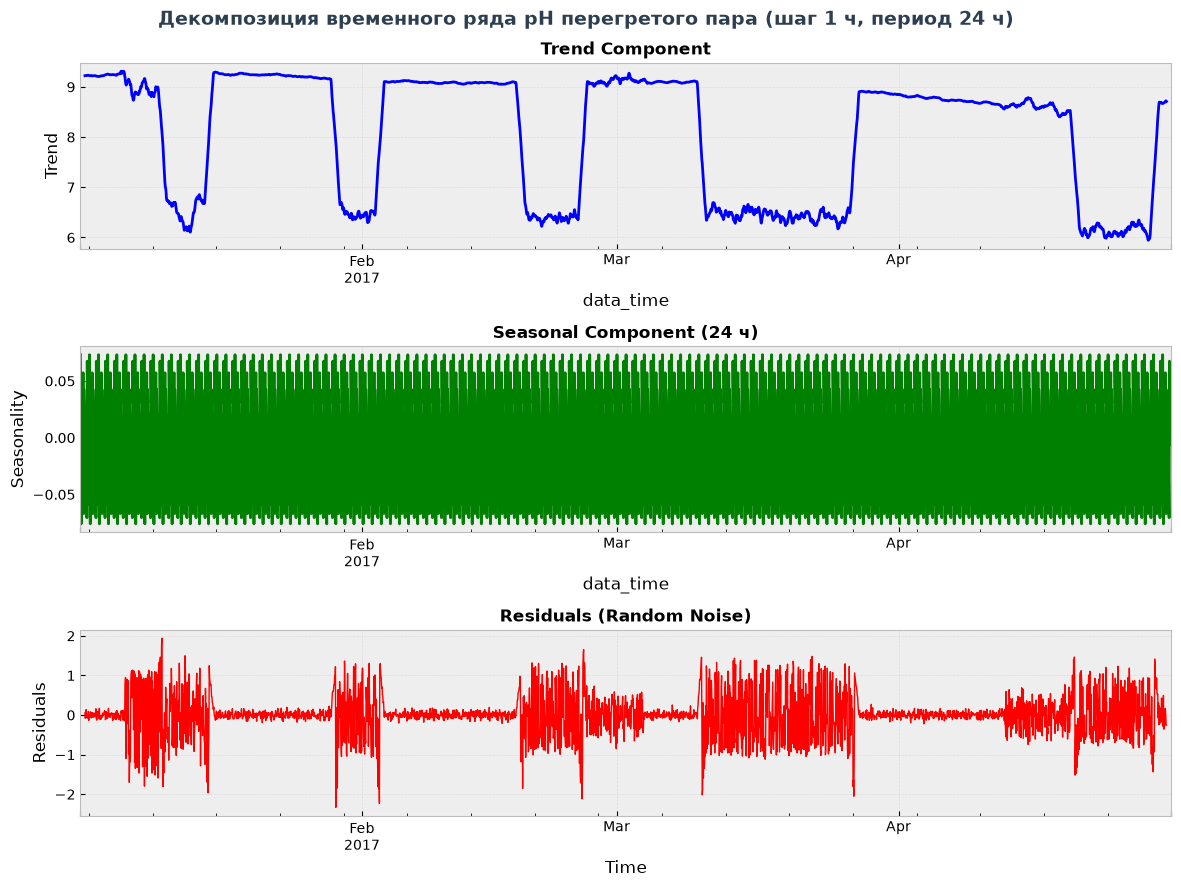

In [67]:
# 'lba10cq201' - pH перегретого пара
data_for_decompose = data_work[data_work.index<'2017-05-01'].copy()
series = data_for_decompose['lba10cq201'].asfreq('1h')
print(f"Длина ряда: {len(series)} точек (~{len(series)/24:.1f} суток)")
print(f"Пропусков: {series.isna().sum()}")
series = series.interpolate(method='time')

decomposed = seasonal_decompose(series, model='additive', period=24)

fig, axes = plt.subplots(3, 1, figsize=(12, 9))

decomposed.trend.plot(ax=axes[0], color='blue', linewidth=2)
axes[0].set_title('Trend Component', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Trend')
axes[0].grid(True, alpha=0.3)

decomposed.seasonal.plot(ax=axes[1], color='green', linewidth=2)
axes[1].set_title('Seasonal Component (24 ч)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Seasonality')
axes[1].grid(True, alpha=0.3)

decomposed.resid.plot(ax=axes[2], color='red', linewidth=1)
axes[2].set_title('Residuals (Random Noise)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Time')
axes[2].set_ylabel('Residuals')
axes[2].grid(True, alpha=0.3)

fig.suptitle('Декомпозиция временного ряда pH перегретого пара (шаг 1 ч, период 24 ч)',
             fontsize=14, fontweight='bold', color='#2C3E50', y=0.98)
plt.tight_layout()
filename = f'Decomposit_pH_time_series.png'
plt.savefig(figures_dir/filename , dpi=150, bbox_inches='tight')
plt.show()

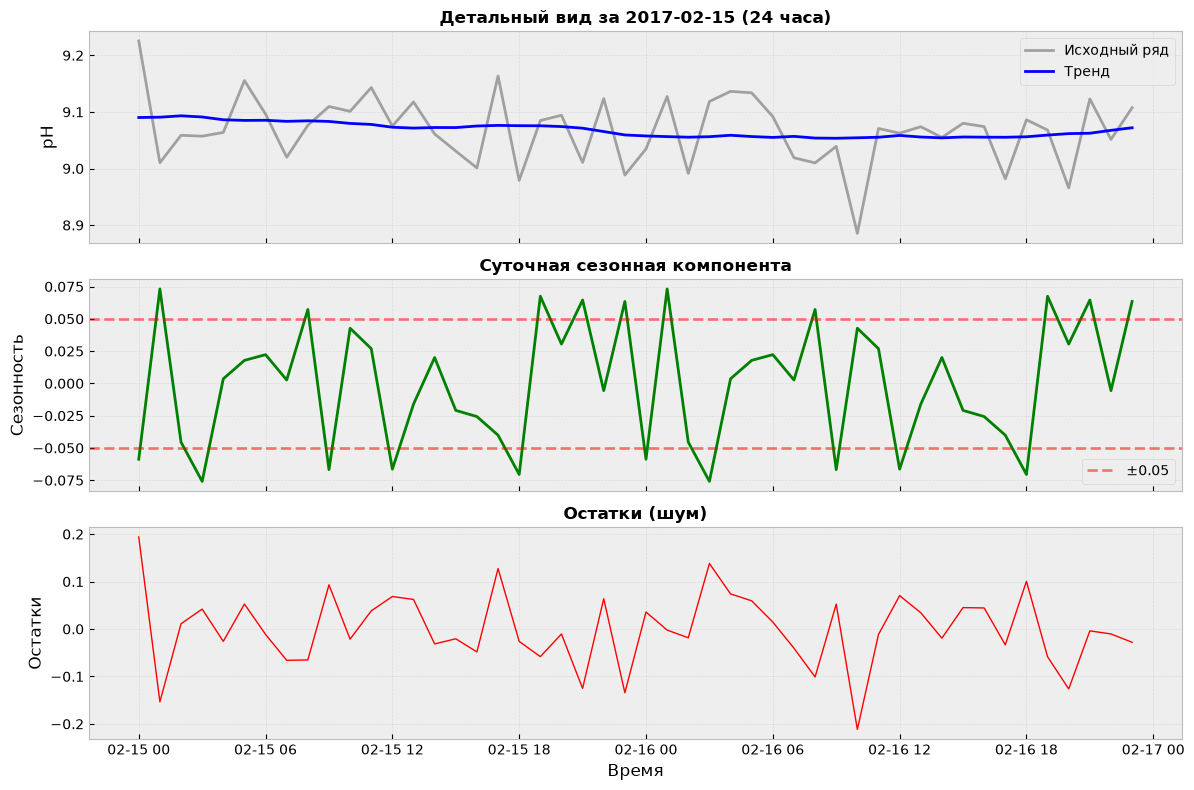

In [68]:
zoom_date = '2017-02-15'
series_zoom = series[zoom_date: '2017-02-16'] # Берем ровно 24 часа
trend_zoom = decomposed.trend[zoom_date: '2017-02-16']
seasonal_zoom = decomposed.seasonal[zoom_date: '2017-02-16']
resid_zoom = decomposed.resid[zoom_date: '2017-02-16']
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

# Исходный ряд + тренд + сезонность (наложенные друг на друга)
axes[0].plot(series_zoom.index, series_zoom, label='Исходный ряд', color='gray', alpha=0.7, linewidth=2)
axes[0].plot(trend_zoom.index, trend_zoom, label='Тренд', color='blue', linewidth=2)
axes[0].set_title(f'Детальный вид за {zoom_date} (24 часа)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('pH')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Сезонная компонента (в увеличенном масштабе)
axes[1].plot(seasonal_zoom.index, seasonal_zoom, color='green', linewidth=2)
axes[1].set_title('Суточная сезонная компонента', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Сезонность')
axes[1].grid(True, alpha=0.3)
# Добавим горизонтальные линии для наглядности ±0.05
axes[1].axhline(y=0.05, color='r', linestyle='--', alpha=0.5, label='±0.05')
axes[1].axhline(y=-0.05, color='r', linestyle='--', alpha=0.5)
axes[1].legend()

# Остатки
axes[2].plot(resid_zoom.index, resid_zoom, color='red', linewidth=1)
axes[2].set_title('Остатки (шум)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Время')
axes[2].set_ylabel('Остатки')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
filename = f'Decomposit_pH_time_series_24h.png'
plt.savefig(figures_dir/filename , dpi=150, bbox_inches='tight')
plt.show()

Для оценки вклада суточной компоненты был проведен детальный анализ декомпозиции временного ряда pH перегретого пара за сутки. Как видно из верхнего графика, на протяжении 24 часов трендовая составляющая остается практически неизменной (колеблется в пределах 9.05–9.10), в то время как исходный сигнал испытывает случайные флуктуации.

Средний график демонстрирует выделенную суточную сезонную компоненту. Её амплитуда строго ограничена диапазоном ±0.05 ед. pH  (красные пунктирные линии).

Сопоставление с графиком остатков (нижний график) показывает, что амплитуда случайного шума (остатков) достигает ±0.2 ед. pH, что в 4 раза превышает амплитуду суточной сезонности.

### <a id="s2_6"></a> 2.6. Проверка стационарности

Декомпозиция временного ряда pH перегретого пара указывает, что тренд - это не плавная линия, а ступенчатая функция. Он скачет между двумя уровнями: ≈9.0 и ≈6.5. Это не тренд в классическом смысле (медленное изменение), это режимное переключение. Ряд проводит дни в одном режиме, потом резко переключается в другой. Остатки неоднородны по дисперсии.  Когда тренд на уровне 6.5, остатки "широкие" (разброс от -2 до +2). В периоды, когда тренд на уровне 9.0, остатки "узкие" (разброс от -0.5 до +0.5). Это гетероскедастичность, связанная с режимом. Тест на структурные сдвиги формально подтвердит, что в ряде есть сдвиги среднего, и найдет их количество. Тест проведем на части данных с 1 января по 1 мая.

In [69]:
def find_breaks(series, name, model="l2", min_size=24):
    """
    Находит структурные сдвиги (Bai-Perron) и печатает краткий вывод.
    PELT (Pruned Exact Linear Time) — это алгоритм поиска точек разладки, 
    который минимизирует сумму стоимости сегментов плюс штраф за количество сдвигов.
    
    Параметры
    ----------
    series : pd.Series — временной ряд
    name   : str       — название параметра
    model  : str       — "l2" (сдвиг среднего) или "rbf" (сдвиг среднего и дисперсии)
    min_size : int     — минимальная длина режима (в точках)
    """
    y = series.dropna().values
    n = len(y)
    # Поиск сдвигов
    algo = rpt.Pelt(model=model, min_size=min_size, jump=1).fit(y)
    bkps = algo.predict(np.log(n) * y.var())
    bkps = [b for b in bkps if b < n]  # убираем конец ряда

    # Средние по режимам
    means = []
    prev = 0
    for b in bkps + [n]:
        means.append(float(y[prev:b].mean()))
        prev = b
        
    print(f"\n{name}")
    print(f"  Точек в ряду:      {n}")
    print(f"  Найдено сдвигов:   {len(bkps)}")
    print(f"  Средние по режимам: {[round(m, 3) for m in means]}")

    if len(bkps) == 0:
        print("  Вывод: структурных сдвигов не обнаружено, ряд однороден.")
    else:
        print("  Вывод: обнаружен структурный сдвиг — ряд не однородный.")
    
    return bkps

for param in ["lba10cq201", "lba10cq202", "lba10cq204"]:
    find_breaks(data_for_decompose[param], name=param, model="l2", min_size=24)


lba10cq201
  Точек в ряду:      2874
  Найдено сдвигов:   10
  Средние по режимам: [9.123, 6.564, 9.228, 6.476, 9.088, 6.419, 9.111, 6.435, 8.725, 6.131, 8.711]
  Вывод: обнаружен структурный сдвиг — ряд не однородный.

lba10cq202
  Точек в ряду:      2874
  Найдено сдвигов:   13
  Средние по режимам: [1.048, 2.826, 3.517, 1.193, 3.538, 0.826, 3.079, 1.019, 0.313, 2.884, 0.788, 1.727, 3.69, 2.338]
  Вывод: обнаружен структурный сдвиг — ряд не однородный.

lba10cq204
  Точек в ряду:      2874
  Найдено сдвигов:   7
  Средние по режимам: [18.69, 51.59, 20.927, 15.789, 7.93, 10.566, 17.794, 43.143]
  Вывод: обнаружен структурный сдвиг — ряд не однородный.


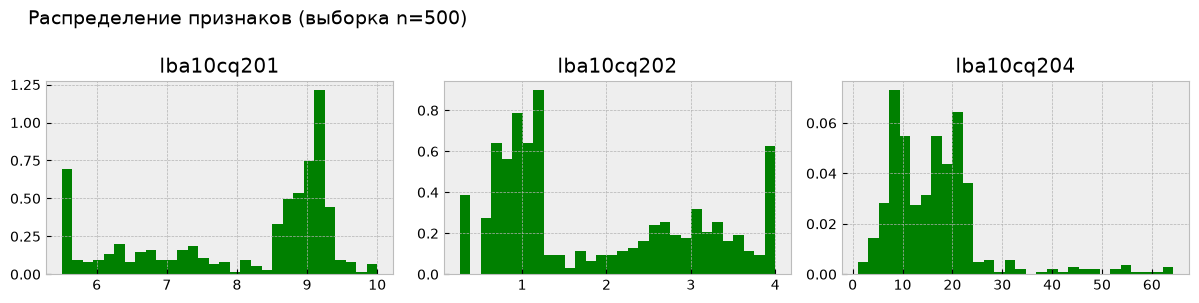

In [70]:
parametrs = ['lba10cq201', 'lba10cq202', 'lba10cq204']
histplot_trends(data_for_decompose, parametrs, n_sample=500)

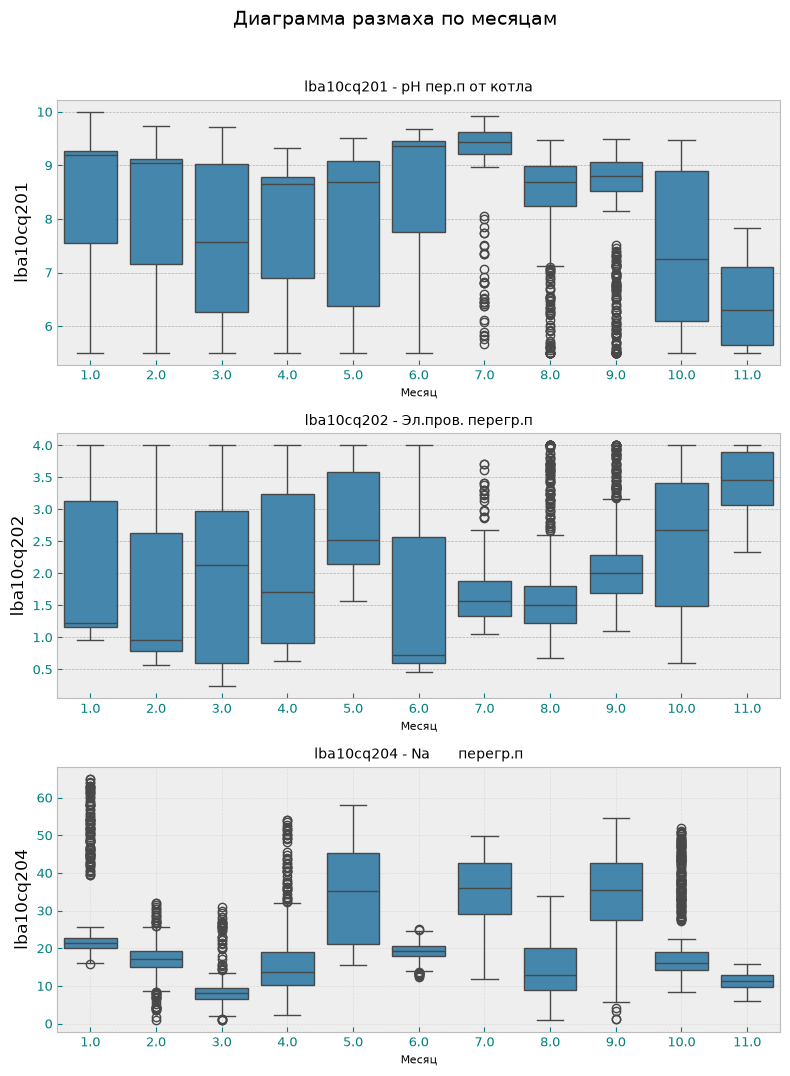

In [71]:
boxplots_for_month(data_work, parametrs)

## <a id="s3"></a> 3 Вывод

Анализ уноса солей с паром проводится только на периодах, когда котёл находится в работе, поскольку физически унос солей возможен лишь при наличии парообразования и отвода пара. В периоды простоя котла (останов, резерв) процессы солепереноса отсутствуют, и такие участки не несут информации о целевом процессе. По этой причине временной ряд содержит значительные разрывы, соответствующие остановкам оборудования. Эти разрывы нельзя «склеивать» — это привело бы к искусственным скачкам и ложным выводам. Поэтому:

  - анализ проводится отдельно для каждого периода работы котла;
  - при обучении моделей необходимо учитывать группировку по периодам, чтобы избежать утечки данных между train и test.

Декомпозиция (аддитивная модель, период 24 ч) выполнена на одном из периодов работы котла, чтобы оценить структуру ряда внутри стабильного режима. 

 - Трендовая компонента не является плавной — она представляет собой ступенчатую функцию, переключающуюся между двумя уровнями (≈9.0 и ≈6.5). Это не классический тренд, а режимное переключение.
 - Сезонная компонента стабильна, амплитуда ≈±0.05, что соответствует суточному циклу.
 - Остатки демонстрируют гетероскедастичность: их разброс существенно выше в режиме с низким средним (≈6.5), чем в режиме с высоким (≈9.0).

Таким образом, ряд не имеет монотонного тренда, а отражает разные режимы работы оборудования. 

Для формального подтверждения режимности выполнен тест на структурные сдвиги (алгоритм PELT, модель l2 — сдвиг среднего). Ключевое наблюдение: средние по режимам группируются в несколько кластеров. Например, для lba10cq202 значения группируются в два устойчивых состояния:

 - Нормальный режим: ≈1.0 (значения 1.048, 1.193, 1.019, 0.313, 0.788, 1.727)
 - Высокий режим: ≈3.1 (значения 2.826, 3.517, 3.538, 3.079, 2.884, 3.69, 2.338)

Параметр возвращается к одним и тем же состояниям через разные промежутки времени. Это классическое режимное переключение, а не дрейф или тренд.
Тест Дики-Фуллера в данной задаче не применялся, поскольку он проверяет только наличие единичного корня и не чувствителен к структурным сдвигам (данные не могут "убегать" в бесконечность из-за ограничения диапазона датчиков, они колеблются вокруг некоторых уровней и давать ложное ощущение стационарности).

Мультимодальный характер эмпирических распределений признаков lba10cq201, lba10cq202, lba10cq204 согласуется с гипотезой о наличии нескольких  различных режимов работы оборудования. Для подтверждения данной гипотезы требуется дополнительный анализ (например, кластеризация или проверка на смесь распределений). На диаграммах размаха по месяцам видно наличие большого количества выбросов. Это могут быть аварийные ситуации и переходные режимы. Поэтому при разметке недостаточно использовать только абсолютный порог. Необходимо сочетать комплексный подход:

  - абсолютные пороги (ПДК)
  - статистические пороги (Z-score > 2.5σ или > 3σ) — для раннего оповещения и выявления аномалий.

Контекст режима — Z-score должен считаться внутри режима, а не по всему ряду.

Сохраненим обработанный датасет для разметки данных и построения моделей.

In [72]:
df_restor.to_csv(data_dir/'df_restor.csv')
print(f'Размер датасета: { df_restor.shape}\n')

Размер датасета: (8759, 12)

